# Scoring data quality

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/wnukmat/robot-learning-notebooks/blob/main/notebooks/4_data_and_hardware/02_data_quality.ipynb) &nbsp; Guide note: [guide-data-quality](https://www.matthewwnuk.com/guide-data-quality.html)

Past a few hundred episodes nobody can watch everything, so quality is scored by program and reviewed by
exception. This notebook computes four cheap scores on every one of 379 real demonstrations, flags the
unusual ones, and measures how consistent the demonstrations of one task are.

In [1]:
# Setup. On Colab this installs the small helper package; where it is already installed it does nothing.
import importlib.util, subprocess, sys
if importlib.util.find_spec("guide_utils") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/wnukmat/robot-learning-notebooks"])

In [2]:
import numpy as np, matplotlib.pyplot as plt
from guide_utils import data, style
style.use()
d = data.libero(); A, S, EP, TK = d["action"], d["state"], d["episode"], d["task"]; eps = np.unique(EP); task = np.array([TK[EP == e][0] for e in eps])

## Four scores

- **Duration**: the length of the episode.
- **Path length**: how far the hand travelled. A direct demonstration has a short path.
- **Jerk**: the third derivative of position. Hesitant or corrected motion has large jerk.
- **Idle time**: the share of steps with a near-zero command.

In [3]:
def scores(e):
    p = S[EP == e][:, :3]; a = A[EP == e]; jerk = np.diff(p, 3, axis=0) * 10 ** 3                    # three differences at 10 steps per second
    return len(p) / 10, np.linalg.norm(np.diff(p, axis=0), axis=1).sum() * 100, np.sqrt((jerk ** 2).sum(1).mean()), (np.abs(a[:, :6]).max(1) < 0.02).mean() * 100
M = np.array([scores(e) for e in eps]); names = ["duration (s)", "path (cm)", "jerk", "idle (%)"]
rel = M.copy()
for t in range(10): rel[task == t, :3] /= np.median(M[task == t, :3], 0)                               # tasks differ, so compare within a task
print("correlation between scores, relative to each task's median:"); print(np.corrcoef(rel[:, :3].T).round(2))

correlation between scores, relative to each task's median:
[[ 1.    0.63 -0.18]
 [ 0.63  1.    0.05]
 [-0.18  0.05  1.  ]]


Path length and duration move together. Jerk is almost independent of both, so it flags different episodes.

## Flag the unusual ones

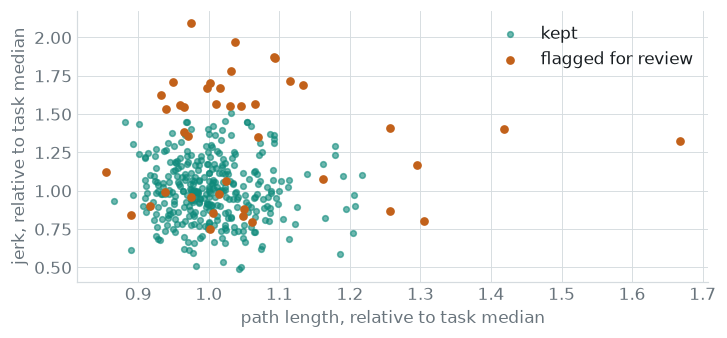

41 of 379 episodes flagged


In [4]:
flag = (rel[:, 1] > 1.25) | (rel[:, 2] > np.percentile(rel[:, 2], 95)) | (M[:, 3] > np.percentile(M[:, 3], 95))
plt.figure(figsize=(7.4, 3.2)); plt.scatter(rel[~flag, 1], rel[~flag, 2], s=14, alpha=0.6, label="kept"); plt.scatter(rel[flag, 1], rel[flag, 2], s=22, color=style.ORANGE, label="flagged for review")
plt.xlabel("path length, relative to task median"); plt.ylabel("jerk, relative to task median"); plt.legend(); plt.show()
print(f"{flag.sum()} of {len(eps)} episodes flagged")

## Look at what was flagged

A score decides what gets looked at. A person decides what it means.

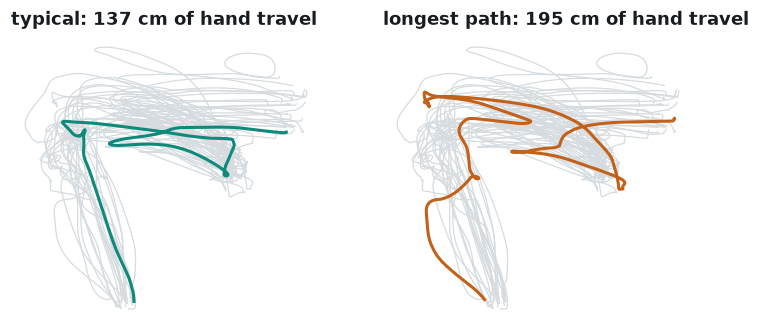

In [5]:
t0 = 8; ids = eps[task == t0]; path_rel = rel[task == t0, 1]; typical, worst = ids[np.argsort(path_rel)[len(ids) // 2]], ids[np.argmax(path_rel)]
fig, ax = plt.subplots(1, 2, figsize=(8, 3.4))
for a, e, c, name in ((ax[0], typical, style.TEAL, "typical"), (ax[1], worst, style.ORANGE, "longest path")):
    for o in ids[:25]: a.plot(S[EP == o][:, 1] * 100, S[EP == o][:, 0] * 100, color="#D5DBDF", lw=0.8)
    p = S[EP == e]; a.plot(p[:, 1] * 100, p[:, 0] * 100, color=c, lw=2); a.set_title(f"{name}: {M[eps == e][0, 1]:.0f} cm of hand travel"); style.bare(a)
plt.show()

## Consistency

Resample every demonstration of one task to 100 steps and measure the spread across demonstrations at
each step. Low spread where the task needs precision is the sign of a clean dataset.

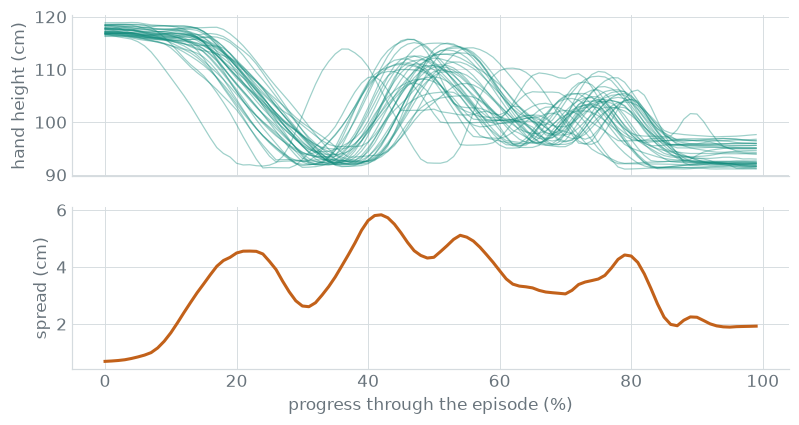

spread is 0.7 cm at its lowest and 5.8 cm at its highest (at 42% of the episode)


In [6]:
Z = np.array([np.interp(np.linspace(0, 1, 100), np.linspace(0, 1, (EP == e).sum()), S[EP == e][:, 2] * 100) for e in ids]); sd = Z.std(0)
fig, ax = plt.subplots(2, 1, figsize=(7.4, 4), sharex=True)
for z in Z: ax[0].plot(z, color=style.TEAL, lw=0.8, alpha=0.4)
ax[0].set_ylabel("hand height (cm)"); ax[1].plot(sd, color=style.ORANGE); ax[1].set_ylabel("spread (cm)"); ax[1].set_xlabel("progress through the episode (%)"); plt.tight_layout(); plt.show()
print(f"spread is {sd.min():.1f} cm at its lowest and {sd.max():.1f} cm at its highest (at {sd.argmax()}% of the episode)")

Part of that spread is timing: two people doing the same thing at different speeds. Shifting each
demonstration in time to best match the average removes it.

In [7]:
mean = Z.mean(0); aligned = np.array([np.roll(z, max(range(-12, 13), key=lambda s: -np.abs(np.roll(z, s) - mean).sum())) for z in Z])
print(f"mean spread before aligning in time: {sd.mean():.2f} cm   after: {aligned.std(0).mean():.2f} cm")

mean spread before aligning in time: 3.35 cm   after: 3.22 cm


## Things to try

- Remove the flagged episodes and recompute the consistency. Does it improve?
- Score smoothness on the commands instead of the positions. Do the same episodes stand out?
- Group by task and rank tasks by how consistent their demonstrations are.